# 02 — Phân tích kết quả thí nghiệm

Notebook này đọc kết quả đã chạy bằng `scripts/run_all.ps1` (thư mục `results/`) và trả lời các câu hỏi E1–E7 của tài liệu (mục 8.2). Nên đọc `01_hieu_dataset.ipynb` trước.

**Cấu hình đã chạy:** dữ liệu thật CIC-DDoS2019 (bản Kaggle), 5 client, 30 vòng FL × 2 epoch cục bộ, Adam lr = 0,001, batch 256; 5 kịch bản × {FedAvg, FedProx μ = 0,01, μ = 0,1} × 3 seed = **45 lượt FL**; baseline 60 epoch; E7 chạy 1 seed.

In [1]:
import sys, glob, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

from fl_ddos import paths
from analysis.plots import SERIES, INK, INK2, GRID, load_fl, color_map, final_round
%matplotlib inline

RES = ROOT / "results"
fl = load_fl()                                   # log từng vòng của mọi lượt FL
base = pd.read_csv(RES / "baselines.csv")        # Centralized, Local-only
pa = pd.read_csv(RES / "per_attack.csv")         # recall theo loại tấn công của mô hình cuối
last = final_round(fl)
# Mỗi phương pháp giữ MỘT màu cố định trong mọi biểu đồ của notebook
COLORS = color_map({"Local-only", "FedAvg", "FedProx μ=0.01", "FedProx μ=0.1", "Centralized",
                    "FedAvg [poison]", "FedTrimmedAvg [poison]"})
print(f"{fl.groupby(['scenario','method','seed']).ngroups} lượt FL, {fl['round'].max()} vòng mỗi lượt")
print("Phương pháp:", sorted(fl.method.unique()))

47 lượt FL, 30 vòng mỗi lượt
Phương pháp: ['FedAvg', 'FedAvg [poison]', 'FedProx μ=0.01', 'FedProx μ=0.1', 'FedTrimmedAvg [poison]']


## 0. Đọc các chỉ số đánh giá thế nào?

Với mỗi flow, mô hình đoán "tấn công" hay "bình thường". So với nhãn thật có 4 trường hợp:

| | Thực tế: tấn công | Thực tế: bình thường |
|---|---|---|
| **Đoán: tấn công** | TP — bắt đúng | FP — báo nhầm (báo động giả) |
| **Đoán: bình thường** | FN — **bỏ sót** | TN — đúng |

| Chỉ số | Công thức | Hiểu đơn giản | Tốt khi |
|---|---|---|---|
| **Recall** (Detection Rate) | TP / (TP + FN) | Trong các flow tấn công, bắt được bao nhiêu %? Bỏ sót DDoS = sập dịch vụ | Cao |
| **Precision** | TP / (TP + FP) | Khi báo "tấn công", đúng bao nhiêu %? | Cao |
| **F1** | 2·P·R / (P + R) | Cân bằng Precision và Recall — **chỉ số chính** | Cao |
| **FPR** (False Alarm Rate) | FP / (FP + TN) | Bao nhiêu % traffic bình thường bị báo nhầm? Nhiều quá thì người vận hành bỏ qua cảnh báo | **Thấp** |
| **AUC** | Diện tích dưới đường ROC | Khả năng xếp hạng flow tấn công cao hơn flow bình thường, **không phụ thuộc ngưỡng 0,5** | Gần 1 |

Không dùng Accuracy làm chỉ số chính vì dữ liệu mất cân bằng: một mô hình đoán "tấn công" cho mọi flow vẫn có Accuracy cao nếu tấn công chiếm đa số.

Mọi chỉ số FL được đo trên **tập test ngày 11/03** do server giữ (không client nào train trên đó).

## 1. Bảng tổng hợp

In [2]:
display(Markdown((RES / "summary.md").read_text(encoding="utf-8")))

| Phương pháp | Kịch bản | F1 | Recall | FPR | AUC | F1 tốt nhất (vòng) | Vòng để F1 ≥ 0,95 | MB truyền | Recall SYN | Recall PortScan |
|---|---|---|---|---|---|---|---|---|---|---|
| Centralized | S1 | 0.9361 ± 0.0527 | 0.8892 ± 0.0901 | 0.0121 ± 0.0048 | 0.9949 ± 0.0032 | — | — | — | 0.8170 ± 0.1498 | 0.9353 ± 0.0197 |
| Local-only | S1 | 0.9441 ± 0.0051 | 0.9037 ± 0.0088 | 0.0117 ± 0.0011 | 0.9960 ± 0.0007 | — | — | — | 0.8422 ± 0.0144 | 0.8942 ± 0.0138 |
| Local-only | S3 | 0.7165 ± 0.0245 | 0.5885 ± 0.0334 | 0.0063 ± 0.0014 | 0.8380 ± 0.0055 | — | — | — | 0.3303 ± 0.0545 | 0.6093 ± 0.0602 |
| FedAvg | S1 | 0.8672 ± 0.0939 | 0.7785 ± 0.1541 | 0.0099 ± 0.0013 | 0.9842 ± 0.0189 | 0.9944 (4) | 1.0 | 14.06 | 0.6340 ± 0.2564 | 0.8980 ± 0.0194 |
| FedAvg | S2a | 0.9229 ± 0.0370 | 0.8658 ± 0.0635 | 0.0144 ± 0.0065 | 0.9930 ± 0.0034 | 0.9925 (3) | 2.0 | 14.06 | 0.7789 ± 0.1058 | 0.9041 ± 0.0203 |
| FedAvg | S2b | 0.9363 ± 0.0051 | 0.9991 ± 0.0001 | 0.2242 ± 0.0190 | 0.9980 ± 0.0004 | 0.9473 (7) | 7.0 | 14.06 | 0.9988 ± 0.0001 | 0.9787 ± 0.0035 |
| FedAvg | S3 | 0.7383 ± 0.0389 | 0.5877 ± 0.0489 | 0.0042 ± 0.0026 | 0.9830 ± 0.0092 | 0.7434 (26) | chưa đạt | 14.06 | 0.3191 ± 0.0811 | 0.7968 ± 0.0100 |
| FedAvg | S4 | 0.9611 ± 0.0224 | 0.9340 ± 0.0438 | 0.0147 ± 0.0090 | 0.9966 ± 0.0014 | 0.9929 (2) | 1.0 | 14.06 | 0.8925 ± 0.0730 | 0.8965 ± 0.0132 |
| FedAvg [poison] | S1 | 0.7873 | 0.6652 | 0.0408 | 0.9391 | 0.9940 (3) | 1.0 | 14.06 | 0.4475 | 0.8219 |
| FedProx μ=0.01 | S1 | 0.9777 ± 0.0051 | 0.9605 ± 0.0107 | 0.0072 ± 0.0022 | 0.9986 ± 0.0002 | 0.9937 (9) | 2.7 | 14.06 | 0.9367 ± 0.0178 | 0.8836 ± 0.0000 |
| FedProx μ=0.01 | S2a | 0.9688 ± 0.0132 | 0.9455 ± 0.0237 | 0.0104 ± 0.0040 | 0.9979 ± 0.0011 | 0.9922 (9) | 3.7 | 14.06 | 0.9116 ± 0.0393 | 0.8919 ± 0.0080 |
| FedProx μ=0.01 | S2b | 0.9889 ± 0.0041 | 0.9906 ± 0.0098 | 0.0211 ± 0.0030 | 0.9976 ± 0.0005 | 0.9919 (18) | 2.0 | 14.06 | 0.9861 ± 0.0160 | 0.8995 ± 0.0127 |
| FedProx μ=0.01 | S3 | 0.8397 ± 0.0960 | 0.7326 ± 0.1359 | 0.0033 ± 0.0030 | 0.9967 ± 0.0023 | 0.8499 (27) | chưa đạt | 14.06 | 0.5581 ± 0.2261 | 0.8714 ± 0.0105 |
| FedProx μ=0.01 | S4 | 0.9693 ± 0.0131 | 0.9439 ± 0.0251 | 0.0056 ± 0.0013 | 0.9983 ± 0.0003 | 0.9929 (8) | 2.3 | 14.06 | 0.9092 ± 0.0417 | 0.8836 ± 0.0000 |
| FedProx μ=0.1 | S1 | 0.9904 ± 0.0044 | 0.9887 ± 0.0085 | 0.0129 ± 0.0003 | 0.9961 ± 0.0015 | 0.9905 (28) | 10.7 | 14.06 | 0.9834 ± 0.0140 | 0.8858 ± 0.0000 |
| FedProx μ=0.1 | S2a | 0.9759 ± 0.0219 | 0.9609 ± 0.0423 | 0.0128 ± 0.0009 | 0.9947 ± 0.0020 | 0.9759 (30) | 19.0 | 14.06 | 0.9371 ± 0.0702 | 0.8836 ± 0.0040 |
| FedProx μ=0.1 | S2b | 0.9918 ± 0.0005 | 0.9955 ± 0.0004 | 0.0200 ± 0.0022 | 0.9938 ± 0.0013 | 0.9918 (20) | 3.3 | 14.06 | 0.9946 ± 0.0007 | 0.8858 ± 0.0000 |
| FedProx μ=0.1 | S3 | 0.7153 ± 0.1052 | 0.5656 ± 0.1353 | 0.0040 ± 0.0022 | 0.9942 ± 0.0006 | 0.7157 (27) | chưa đạt | 14.06 | 0.2804 ± 0.2248 | 0.8782 ± 0.0070 |
| FedProx μ=0.1 | S4 | 0.9915 ± 0.0022 | 0.9903 ± 0.0047 | 0.0121 ± 0.0009 | 0.9959 ± 0.0018 | 0.9921 (27) | 8.7 | 14.06 | 0.9861 ± 0.0077 | 0.8836 ± 0.0040 |
| FedTrimmedAvg [poison] | S1 | 0.9619 | 0.9387 | 0.0216 | 0.9944 | 0.9946 (4) | 1.0 | 14.06 | 0.9010 | 0.8744 |


Bảng đầy đủ khá dày. Gọn hơn: **F1 ở vòng cuối, trung bình 3 seed**, theo phương pháp × kịch bản (màu càng đậm càng tốt):

In [3]:
rows = [last[["method", "scenario", "seed", "f1"]],
        base[base.client.astype(str).isin(["all", "mean"])][["method", "scenario", "seed", "f1"]]]
d = pd.concat(rows)
d = d[~d.method.str.contains("poison")]
pv = d.pivot_table(index="method", columns="scenario", values="f1", aggfunc="mean")
pv = pv.reindex(["Local-only", "FedAvg", "FedProx μ=0.01", "FedProx μ=0.1", "Centralized"])
pv.style.format("{:.3f}", na_rep="—").background_gradient(cmap="Blues", vmin=0.6, vmax=1.0, axis=None)

scenario,S1,S2a,S2b,S3,S4
method,,,,,
Local-only,0.944,—,—,0.716,—
FedAvg,0.867,0.923,0.936,0.738,0.961
FedProx μ=0.01,0.978,0.969,0.989,0.840,0.969
FedProx μ=0.1,0.990,0.976,0.992,0.715,0.992
Centralized,0.936,—,—,—,—


Ô "—" là cấu hình không chạy (Centralized chỉ cần chạy một lần vì gộp mọi client là như nhau ở mọi kịch bản; Local-only chạy cho S1 và S3).

## 2. E1 — FL có gần bằng huấn luyện tập trung không? (S1)

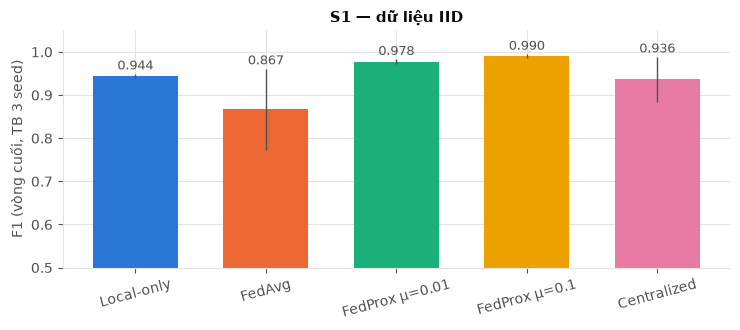

,mean,std
method,,
Local-only,0.9441,0.0051
FedAvg,0.8672,0.0939
FedProx μ=0.01,0.9777,0.0051
FedProx μ=0.1,0.9904,0.0044
Centralized,0.9361,0.0527


In [4]:
s1 = d[d.scenario == "S1"].groupby("method")["f1"].agg(["mean", "std"]).reindex(
    ["Local-only", "FedAvg", "FedProx μ=0.01", "FedProx μ=0.1", "Centralized"])
colors = COLORS
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(s1.index, s1["mean"], yerr=s1["std"], color=[colors[m] for m in s1.index],
       error_kw={"ecolor": INK2, "lw": 1}, width=0.65)
for i, (m, r) in enumerate(s1.iterrows()):
    ax.text(i, r["mean"] + r["std"] + 0.01, f"{r['mean']:.3f}", ha="center", fontsize=9, color=INK2)
ax.set_ylim(0.5, 1.05); ax.set_ylabel("F1 (vòng cuối, TB 3 seed)"); ax.set_title("S1 — dữ liệu IID")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
s1.round(4)

**Kết luận E1:**
- FedProx (cả hai mức μ) **đạt và vượt** Centralized → FL không làm mất độ chính xác khi dữ liệu IID.
- Centralized **không phải "cận trên"** như tài liệu giả định, và có độ lệch chuẩn lớn giữa các seed. Lý do giống FedAvg (phần 4): train 60 epoch liên tục trên ngày 12/01 khiến mô hình khớp quá mức với ngày đó.
- FedAvg có thanh lỗi (độ lệch chuẩn) lớn nhất → kết quả phụ thuộc nhiều vào seed.

## 3. E2 — Non-IID làm FedAvg giảm bao nhiêu?

In [5]:
fa = d[d.method == "FedAvg"].groupby("scenario")["f1"].agg(["mean", "std", "min", "max"]).round(4)
fa["Mô tả"] = ["IID", "Dirichlet α=0,5", "Dirichlet α=0,1", "Theo loại tấn công", "Lệch kích thước"]
fa

,mean,std,min,max,Mô tả
scenario,,,,,
S1,0.8672,0.0939,0.7961,0.9737,IID
S2a,0.9229,0.0370,0.8828,0.9557,"Dirichlet α=0,5"
S2b,0.9363,0.0051,0.9327,0.9421,"Dirichlet α=0,1"
S3,0.7383,0.0389,0.6939,0.7662,Theo loại tấn công
S4,0.9611,0.0224,0.9353,0.9750,Lệch kích thước


**Kết luận E2:** S3 (mỗi chi nhánh gặp loại DDoS khác nhau) là kịch bản FedAvg tệ nhất (F1 ≈ 0,74). Điều bất ngờ là S1 (IID) **không** tốt nhất cho FedAvg — vì hiện tượng suy giảm theo vòng ở phần 4 làm kết quả vòng cuối dao động mạnh giữa các seed. Cần nhìn cả đường hội tụ, không chỉ con số cuối cùng.

Lưu ý thêm với **S2b**: F1 ≈ 0,94 nhưng xem bảng tổng hợp — **FPR lên tới ~0,22** (22% traffic bình thường bị báo nhầm), cao gấp ~20 lần các kịch bản khác. F1 cao vì recall gần 1 (mô hình nghiêng hẳn về đoán "tấn công"). Đây là ví dụ cho thấy phải đọc F1 cùng FPR.

## 4. ⭐ Phát hiện chính: FedAvg đạt đỉnh sớm rồi suy giảm

Vẽ F1, Recall và FPR theo từng vòng cho S1 (mỗi đường mảnh là một seed, đường đậm là trung bình):

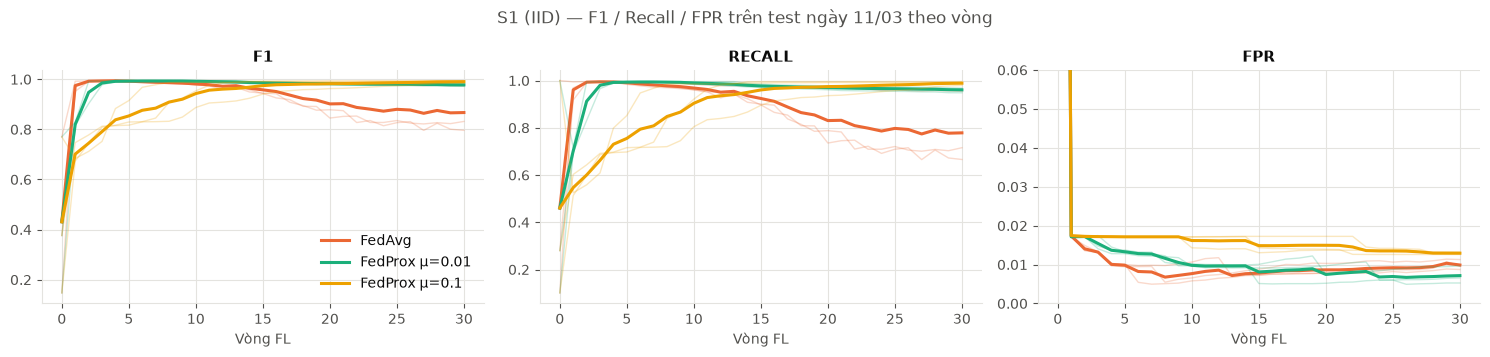

In [6]:
methods = ["FedAvg", "FedProx μ=0.01", "FedProx μ=0.1"]
colors = COLORS
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, metric in zip(axes, ["f1", "recall", "fpr"]):
    for m in methods:
        g = fl[(fl.scenario == "S1") & (fl.method == m)]
        for _, gs in g.groupby("seed"):
            ax.plot(gs["round"], gs[metric], color=colors[m], alpha=0.25, lw=1)
        mean = g.groupby("round")[metric].mean()
        ax.plot(mean.index, mean.values, color=colors[m], lw=2.2, label=m)
    ax.set_title(metric.upper()); ax.set_xlabel("Vòng FL")
axes[2].set_ylim(0, 0.06); axes[0].legend()
fig.suptitle("S1 (IID) — F1 / Recall / FPR trên test ngày 11/03 theo vòng", color=INK2)
plt.tight_layout(); plt.show()

**Đọc biểu đồ:**
- **FedAvg (cam)** lên tới F1 ≈ 0,99 chỉ sau vài vòng, rồi **tụt dần**. FPR gần như không đổi → phần tụt nằm ở **Recall**: mô hình ngày càng **bỏ sót** tấn công.
- **FedProx μ = 0,1 (vàng)** tăng chậm hơn nhưng **giữ ổn định** đến vòng 30.

So sánh F1 **tốt nhất** (ở bất kỳ vòng nào) với F1 **vòng cuối**, trên mọi kịch bản:

In [7]:
g = fl[fl["round"] > 0]
best = g.loc[g.groupby(["scenario", "method", "seed"])["f1"].idxmax()]
cmp = pd.DataFrame({
    "F1 tốt nhất": best.groupby(["scenario", "method"])["f1"].mean(),
    "ở vòng (TB)": best.groupby(["scenario", "method"])["round"].mean(),
    "F1 vòng cuối": last.groupby(["scenario", "method"])["f1"].mean(),
})
cmp["Mất đi"] = cmp["F1 tốt nhất"] - cmp["F1 vòng cuối"]
cmp = cmp[~cmp.index.get_level_values("method").str.contains("poison")]
cmp.round(3).style.format("{:.3f}").background_gradient(subset=["Mất đi"], cmap="Reds", vmin=0, vmax=0.2)

**Thủ phạm là SYN.** Recall theo loại tấn công của mô hình cuối (trung bình 3 seed):

In [8]:
att = [c for c in pa.columns if c not in ("method", "scenario", "client", "seed", "BENIGN")]
fl_pa = pa[pa.client == "global"]
t = fl_pa[fl_pa.scenario == "S1"].groupby("method")[att].mean()
t = t.loc[[m for m in methods if m in t.index]]
t.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0, vmax=1, axis=None)

,LDAP,MSSQL,NetBIOS,PortScan,SYN,UDP,UDP-Lag
method,,,,,,,
FedAvg,0.993,0.998,0.943,0.898,0.634,1.000,0.956
FedProx μ=0.01,0.993,0.998,0.943,0.884,0.937,1.000,0.947
FedProx μ=0.1,0.993,0.998,0.975,0.886,0.983,1.000,0.947


Các loại khác đều ≥ 0,88, riêng **SYN**: FedAvg chỉ bắt được khoảng 60%, FedProx μ = 0,1 bắt ~98%.

**Giải thích** (xem `01_hieu_dataset.ipynb`, phần 8): ngày train chỉ có 533 flow SYN, ngày test có 48.840 flow SYN với nhiều biến thể chưa thấy. Càng train nhiều vòng, mô hình càng "chuyên" vào dữ liệu ngày 12/01 và đường ranh giới quanh SYN co lại — **overfitting do lệch phân phối giữa hai ngày**. Số hạng FedProx $\frac{\mu}{2}\lVert w - w_t \rVert^2$ không cho trọng số mỗi client trôi xa mô hình toàn cục, nên hoạt động như một dạng **regularization**.

**Ý nghĩa thực tế:** cần **early stopping** — dừng ở vòng có F1 tốt nhất trên một tập validation — hoặc dùng FedProx. Ghi điểm này vào phần Thảo luận của báo cáo.

## 5. E3 — FedProx có cứu được Non-IID không?

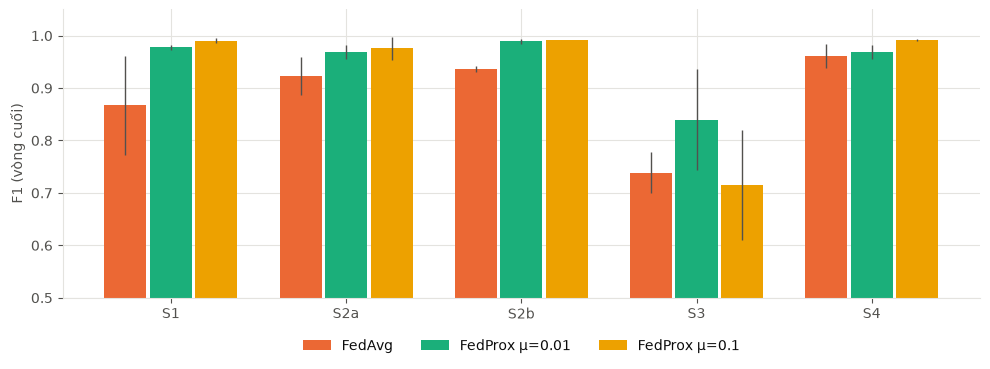

In [9]:
dd = d[d.method.isin(methods)]
fig, ax = plt.subplots(figsize=(10, 3.8))
scen = ["S1", "S2a", "S2b", "S3", "S4"]
w = 0.26
for i, m in enumerate(methods):
    s = dd[dd.method == m].groupby("scenario")["f1"].agg(["mean", "std"]).reindex(scen)
    ax.bar(np.arange(len(scen)) + (i - 1) * w, s["mean"], w - 0.02, yerr=s["std"],
           color=colors[m], label=m, error_kw={"ecolor": INK2, "lw": 1})
ax.set_xticks(range(len(scen)), scen); ax.set_ylim(0.5, 1.05); ax.set_ylabel("F1 (vòng cuối)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

**Kết luận E3:**
- Ở **S1, S2a, S2b, S4**: FedProx μ = 0,1 tốt nhất và **độ lệch chuẩn rất nhỏ** — ổn định giữa các seed.
- Ở **S3**: không phương pháp nào tốt, và kết quả **dao động mạnh** (độ lệch chuẩn ~±0,10). μ = 0,01 có trung bình cao nhất nhưng không đủ ổn định để kết luận chắc chắn. FedProx không giải quyết được gốc rễ của S3 (phần 7).

## 6. E4 — Client ít dữ liệu có bị thiệt không? (S4)

Mỗi vòng, mỗi client đánh giá mô hình toàn cục trên **tập validation cục bộ** của mình. `client_f1_std` = độ lệch F1 giữa các client (thấp = công bằng); `client_f1_min` = F1 của client kém nhất.

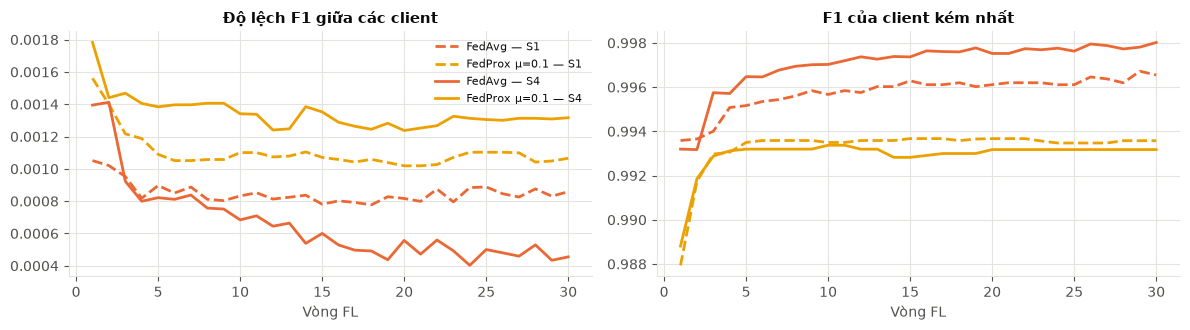

client_f1_std  client_f1_min
scenario method                                              
S1       FedAvg                         0.0009         0.9965
         FedAvg [poison]                0.0007         0.9942
         FedProx μ=0.01                 0.0008         0.9966
         FedProx μ=0.1                  0.0011         0.9936
         FedTrimmedAvg [poison]         0.0004         0.9979
S4       FedAvg                         0.0005         0.9980
         FedProx μ=0.01                 0.0007         0.9974
         FedProx μ=0.1                  0.0013         0.9932

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, metric, title in [(axes[0], "client_f1_std", "Độ lệch F1 giữa các client"),
                          (axes[1], "client_f1_min", "F1 của client kém nhất")]:
    for sc, ls in [("S1", "--"), ("S4", "-")]:
        for m in ["FedAvg", "FedProx μ=0.1"]:
            g = fl[(fl.scenario == sc) & (fl.method == m)].groupby("round")[metric].mean()
            ax.plot(g.index, g.values, ls, color=colors[m], label=f"{m} — {sc}")
    ax.set_title(title); ax.set_xlabel("Vòng FL")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
fl[fl["round"] == fl["round"].max()].groupby(["scenario", "method"])[["client_f1_std", "client_f1_min"]].mean() \
    .loc[["S1", "S4"]].round(4)

**Kết luận E4:** Độ lệch F1 giữa các client ở S4 (nét liền) tương đương S1 (nét đứt), và client kém nhất vẫn đạt F1 cao → client nhỏ (chỉ 5% dữ liệu) **không bị thiệt** đáng kể, vì ở S4 mọi client có cùng phân phối nhãn, chỉ khác số lượng. Trọng số $n_k/n$ của FedAvg không gây hại trong trường hợp này.

Để ý thêm: trên **validation cục bộ** (cùng ngày 12/01 với dữ liệu train) mọi client đạt F1 ≈ 0,99, nhưng trên **test ngày 11/03** chỉ còn 0,87–0,99. Khoảng cách này là thêm một bằng chứng cho **lệch phân phối giữa hai ngày** — và là lý do không được chọn mô hình/dừng sớm dựa trên validation cùng ngày rồi báo cáo như kết quả cuối.

## 7. E5 — Mô hình FL có bắt được tấn công mà chi nhánh mình chưa thấy? (S3)

Heatmap: hàng = mô hình (Local-only của từng client vs mô hình FL), cột = loại tấn công ở ngày test, ô = recall (trung bình 3 seed).

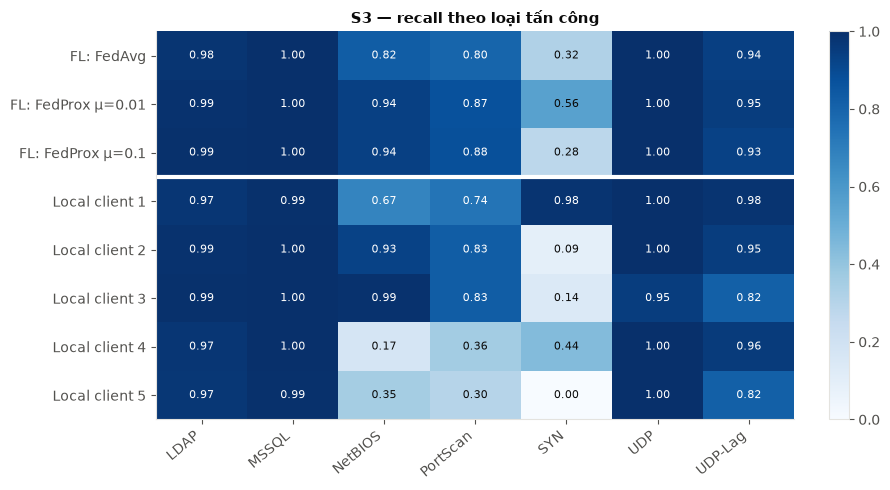

In [11]:
s3 = pa[pa.scenario == "S3"].copy()
s3["Mô hình"] = np.where(s3.method == "Local-only", "Local client " + s3.client.astype(str), "FL: " + s3.method)
mat = s3.groupby("Mô hình")[att].mean()
order = [r for r in mat.index if r.startswith("FL")] + sorted(r for r in mat.index if r.startswith("Local"))
mat = mat.loc[order]
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(mat.values, cmap="Blues", vmin=0, vmax=1, aspect="auto"); ax.grid(False)
for (i, j), v in np.ndenumerate(mat.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else INK)
ax.set_xticks(range(len(att)), att, rotation=40, ha="right"); ax.set_yticks(range(len(mat)), mat.index)
ax.axhline(2.5, color="white", lw=3)
fig.colorbar(im, ax=ax, fraction=0.03); ax.set_title("S3 — recall theo loại tấn công")
plt.tight_layout(); plt.show()

Nhắc lại cách chia S3: client 1 giữ SYN + UDP + UDP-Lag; client 2 giữ DNS/LDAP/NTP; client 3 MSSQL/NetBIOS/SNMP; client 4 TFTP/WebDDoS; client 5 chỉ BENIGN + ít UDP.

**Hai mặt của FL:**

✅ **Truyền kiến thức giữa chi nhánh:** client 4, 5 học riêng chỉ bắt được 17–35% NetBIOS và ~30–36% PortScan; mô hình FL bắt được 82–94% NetBIOS và 80–88% PortScan. Chi nhánh chưa từng gặp một kiểu tấn công vẫn được bảo vệ nhờ kiến thức của chi nhánh khác — **đúng mục tiêu của đồ án**.

❌ **Pha loãng kiến thức hiếm:** client 1 học riêng bắt được ~98% SYN, nhưng mô hình FL chỉ bắt được 28–56%. Lý do: FedAvg gộp trọng số theo số mẫu $n_k/n$; 533 flow SYN chỉ là ~0,4% tổng dữ liệu, và 4/5 client "kéo" mô hình về phía "flow giống SYN là bình thường". Đây chính là vấn đề mà **FLAD** (Doriguzzi-Corin & Siracusa, 2024 — mục 2 của tài liệu) giải quyết bằng cách giao thêm vòng huấn luyện cho client có loại tấn công khó.

→ Gợi ý hướng mở rộng cho báo cáo: thử **FLAD** / epoch thích ứng theo client, hoặc **personalized FL** (giữ một phần mô hình riêng tại mỗi chi nhánh).

## 8. Khả năng tổng quát hóa — PortScan (chưa từng thấy khi train)

In [12]:
ps = pa[pa.client.astype(str).isin(["global", "all"])].groupby(["scenario", "method"])["PortScan"].agg(["mean", "std"])
ps = ps[~ps.index.get_level_values("method").str.contains("poison")]
ps.round(3).unstack("method")["mean"]

method,Centralized,FedAvg,FedProx μ=0.01,FedProx μ=0.1
scenario,,,,
S1,0.935,0.898,0.884,0.886
S2a,NaN,0.904,0.892,0.884
S2b,NaN,0.979,0.900,0.886
S3,NaN,0.797,0.871,0.878
S4,NaN,0.896,0.884,0.884


PortScan không có trong dữ liệu train ở bất kỳ client nào, nhưng mô hình vẫn bắt được **~80–98%** — vì PortScan có hành vi gần giống các tấn công đã học (nhiều flow ngắn, ít/không có phản hồi). Lưu ý tập test chỉ có 438 flow PortScan nên con số này có sai số lớn.

## 9. Chi phí truyền thông — FL so với gửi dữ liệu thô

In [13]:
n_params = 11714   # in ra khi server khởi động: 25 đặc trưng → 128 → 64 → 2
rounds, K = 30, 5
fl_mb = 2 * K * n_params * 4 * rounds / 1e6
rows = sum(len(pd.read_parquet(f, columns=["binary"])) for f in (ROOT / "data" / "S1").glob("client_*.parquet"))
raw_feat_mb = rows * 25 * 4 / 1e6
pcap_note = "PCAP gốc CIC-DDoS2019: hàng chục GB"
pd.DataFrame({"Cách làm": ["FL: gửi trọng số (30 vòng, lên + xuống, 5 client)",
                           "Gửi vector đặc trưng của mọi flow về server",
                           "Gửi gói tin thô (PCAP)"],
              "Dung lượng": [f"{fl_mb:.1f} MB", f"{raw_feat_mb:.1f} MB", pcap_note]})

,Cách làm,Dung lượng
0,"FL: gửi trọng số (30 vòng, lên + xuống, 5 client)",14.1 MB
1,Gửi vector đặc trưng của mọi flow về server,14.4 MB
2,Gửi gói tin thô (PCAP),PCAP gốc CIC-DDoS2019: hàng chục GB


Với dataset nhỏ này, gửi vector đặc trưng (~14 MB) và gửi trọng số (~14 MB) **tương đương nhau** về dung lượng. Lợi ích của FL ở đây chủ yếu là **riêng tư** (không lộ IP, port, thời điểm của từng flow), không phải tiết kiệm băng thông. Khi traffic thật lớn (hàng triệu flow/ngày, hoặc phải gửi PCAP), chi phí FL **không đổi** còn chi phí gửi dữ liệu tăng tuyến tính → FL mới có lợi thế rõ về băng thông. Nên viết trung thực điểm này trong báo cáo.

## 10. E7 — Một client bị chiếm và đầu độc dữ liệu (S1, seed 0)

Client 1 bị đảo nhãn (tấn công ↔ bình thường) rồi tham gia FL như bình thường.

In [14]:
e7 = last[(last.scenario == "S1") & (last.seed == 0) &
          (last.method.isin(["FedAvg", "FedAvg [poison]", "FedTrimmedAvg [poison]"]))]
e7 = e7.set_index("method")[["f1", "recall", "fpr", "auc"]].round(4)
e7.loc[["FedAvg", "FedAvg [poison]", "FedTrimmedAvg [poison]"]]

,f1,recall,fpr,auc
method,,,,
FedAvg,0.7961,0.6658,0.0113,0.9626
FedAvg [poison],0.7873,0.6652,0.0408,0.9391
FedTrimmedAvg [poison],0.9619,0.9387,0.0216,0.9944


- Đầu độc làm **FPR tăng ~4 lần** với FedAvg (client đảo nhãn dạy mô hình rằng flow bình thường là tấn công).
- **FedTrimmedAvg** (bỏ 20% giá trị lớn nhất/nhỏ nhất ở mỗi tham số trước khi lấy trung bình) đưa F1 lên 0,96 và **giảm FPR còn một nửa** (0,041 → 0,022) — tuy vẫn cao gấp đôi FedAvg trên dữ liệu sạch (0,011), tức là chưa loại bỏ hết ảnh hưởng của client độc.
- ⚠️ Chưa đủ để kết luận chắc chắn: mới chạy **1 seed**, và chưa chạy **FedTrimmedAvg trên dữ liệu sạch** — nên chưa tách được bao nhiêu phần cải thiện đến từ việc loại client độc, bao nhiêu từ việc FedTrimmedAvg vốn ổn định hơn (giống FedProx ở phần 4). Muốn chắc chắn, chạy thêm:
  ```powershell
  .\scripts\fl_run.ps1 "scenario='S1' strategy='trimmed' seed=0"   # trimmed, dữ liệu sạch
  .\scripts\fl_run.ps1 "scenario='S1' poison-clients='0' strategy='trimmed' seed=1"
  ```

## 11. Mô hình tốt nhất nhìn từ gần — ma trận nhầm lẫn

In [15]:
from fl_ddos.task import DDoSNet, load_global_test, predict, test_labels, metrics
from sklearn.metrics import confusion_matrix
model_path = RES / "fl" / "S1_mu0.1_fedavg_seed0_global.pt"
model = DDoSNet(); model.load_state_dict(torch.load(model_path, map_location="cpu"))
y, p, _ = predict(model, load_global_test(), "cpu")
labels = test_labels()
pred = (p >= 0.5).astype(int)
cm = pd.DataFrame(confusion_matrix(y, pred), index=["Thực: BENIGN", "Thực: DDoS"], columns=["Đoán: BENIGN", "Đoán: DDoS"])
display(cm)
per = pd.DataFrame({"Số flow": pd.Series(labels).value_counts(),
                    "Tỉ lệ bị đoán là DDoS": pd.Series(pred).groupby(labels).mean()}).sort_values("Số flow", ascending=False)
per.style.format({"Tỉ lệ bị đoán là DDoS": "{:.3f}", "Số flow": "{:,}"})

,Đoán: BENIGN,Đoán: DDoS
Thực: BENIGN,28848,378
Thực: DDoS,215,48276


,Số flow,Tỉ lệ bị đoán là DDoS
BENIGN,"29,226",0.013
SYN,"29,167",0.995
UDP,"16,156",1.000
MSSQL,"2,211",0.998
PortScan,438,0.886
LDAP,306,0.993
NetBIOS,175,0.994
UDP-Lag,38,0.947


Với dòng BENIGN, "tỉ lệ bị đoán là DDoS" chính là **FPR**; với các dòng tấn công, đó là **recall** của loại đó.

## 12. Tổng kết cho báo cáo

| Câu hỏi | Trả lời ngắn | Bằng chứng |
|---|---|---|
| E1: FL có gần tập trung? | Có — FedProx còn vượt Centralized ở S1 | Phần 2 |
| E2: Non-IID ảnh hưởng FedAvg? | Nặng nhất ở S3 (F1 ≈ 0,74); S2b làm FPR tăng vọt | Phần 3 |
| (Phát hiện thêm) | FedAvg đạt đỉnh ở vòng 2–4 rồi suy giảm do lệch phân phối SYN giữa hai ngày | Phần 4 |
| E3: FedProx có giúp? | Có, rõ ở 4/5 kịch bản (ổn định hơn nhiều); không giải quyết được S3 | Phần 5 |
| E4: Client nhỏ có thiệt? | Không đáng kể khi phân phối nhãn giống nhau | Phần 6 |
| E5: Bắt được tấn công chi nhánh chưa thấy? | Có (NetBIOS, PortScan) — nhưng kiến thức hiếm (SYN) bị pha loãng | Phần 7 |
| E6: So với chỉ dùng luật Suricata? | **Chưa chạy** — cần lab Docker (`lab/`) | — |
| E7: Đầu độc? | FedAvg tăng FPR ~4×; FedTrimmedAvg chống được (cần thêm seed) | Phần 10 |

**Hạn chế nên nêu:** dataset cũ (2019) và nhiễu nhãn (UDP-Lag 75% là TCP, cờ SYN = 0); ngày train thiếu SYN; test thiếu NTP/DNS/TFTP/SNMP; FL mô phỏng trên một máy; chưa có secure aggregation / differential privacy; E7 mới 1 seed; E6 chưa thực hiện.